=== Product weekly demand scenarios ===
Product  Weekly_Low  Weekly_Base  Weekly_High
     A1      591.08          962      1332.92
     A2      931.32         1923      2914.68
     A3     1212.10         2500      3787.90
     B1      798.54         1154      1509.46
     B2      824.50         1538      2251.50

=== Weekly Part Demand Scenarios (Demand Fulfillment Capacity Plan) ===
Part  Weekly_Low  Weekly_Base  Weekly_High
  P1    11320.78      20962.0     30603.22
  P2     6385.60      11156.0     15926.40
  P3     4018.66       6154.0      8289.34
  P4     4952.60       9231.0     13509.40
  P5     3355.52       6923.0     10490.48
  P6     2240.08       4038.0      5835.92
  P7     7023.28      13844.0     20664.72
  P8     3194.16       4616.0      6037.84
  P9     4286.84       8846.0     13405.16
 P10     6327.00      12308.0     18289.00
 P11     4480.16       8076.0     11671.84
 P12     5662.32      10000.0     14337.68
 P13     2831.16       5000.0      7168.84
 P14     

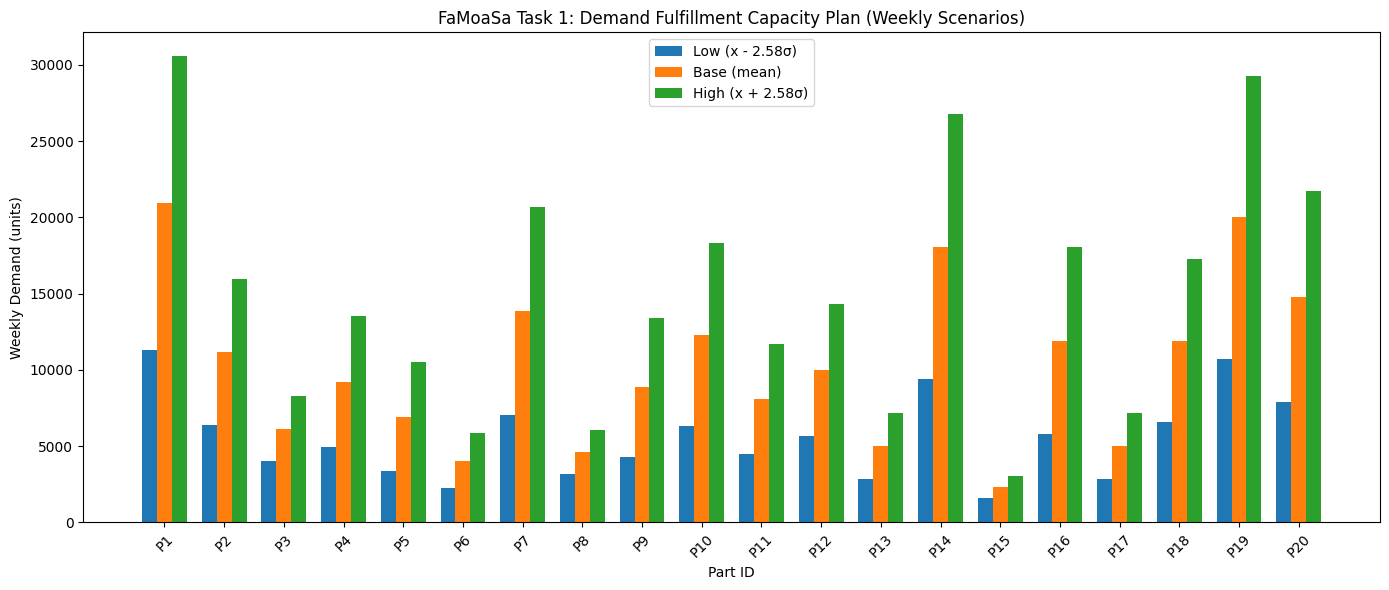

In [1]:
#weekly demand 28/10/2025
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1. INPUTS
# -----------------------------

# Weekly demand forecast for each finished product (Year +1)
product_mean = {
    "A1": 962,
    "A2": 1923,
    "A3": 2500,
    "B1": 1154,
    "B2": 1538,
}

# Weekly standard deviation for each finished product (Year +1)
# TODO: replace these placeholder values with the actual σ in your case packet
product_std = {
    "A1": 144,
    "A2": 385,
    "A3": 500,
    "B1": 138,
    "B2": 277,
}

# Bill of Materials (BOM): parts used per unit of each finished product
# bom[product][part] = quantity of that part in one unit of that product
bom = {
    "A1": {
        "P1": 1, "P2": 4, "P3": 0, "P4": 0, "P5": 0,
        "P6": 1, "P7": 0, "P8": 0, "P9": 0, "P10": 1,
        "P11": 2, "P12": 4, "P13": 2, "P14": 0, "P15": 0,
        "P16": 0, "P17": 2, "P18": 4, "P19": 0, "P20": 0,
    },
    "A2": {
        "P1": 2, "P2": 0, "P3": 0, "P4": 1, "P5": 1,
        "P6": 0, "P7": 4, "P8": 0, "P9": 2, "P10": 4,
        "P11": 0, "P12": 0, "P13": 0, "P14": 4, "P15": 0,
        "P16": 1, "P17": 0, "P18": 1, "P19": 2, "P20": 2,
    },
    "A3": {
        "P1": 4, "P2": 2, "P3": 0, "P4": 2, "P5": 2,
        "P6": 0, "P7": 0, "P8": 0, "P9": 2, "P10": 1,
        "P11": 0, "P12": 0, "P13": 0, "P14": 2, "P15": 0,
        "P16": 4, "P17": 0, "P18": 0, "P19": 4, "P20": 3,
    },
    "B1": {
        "P1": 4, "P2": 2, "P3": 4, "P4": 2, "P5": 0,
        "P6": 0, "P7": 0, "P8": 4, "P9": 0, "P10": 1,
        "P11": 0, "P12": 0, "P13": 0, "P14": 2, "P15": 2,
        "P16": 0, "P17": 0, "P18": 0, "P19": 4, "P20": 3,
    },
    "B2": {
        "P1": 1, "P2": 0, "P3": 1, "P4": 0, "P5": 0,
        "P6": 2, "P7": 4, "P8": 0, "P9": 0, "P10": 0,
        "P11": 4, "P12": 4, "P13": 2, "P14": 2, "P15": 0,
        "P16": 0, "P17": 2, "P18": 4, "P19": 1, "P20": 0,
    },
}

# Constants
Z = 2.5758        # safety factor for 99.9% service


# -----------------------------
# 2. PRODUCT-LEVEL WEEKLY DEMAND SCENARIOS
# -----------------------------
# For each finished product j:
#   Weekly_Low  = (mean_j - 3.29*stdev_j) / 52
#   Weekly_Base =  mean_j / 52
#   Weekly_High = (mean_j + 3.29*stdev_j) / 52

product_records = []
for product in product_mean:
    mu = product_mean[product]
    sd = product_std[product]

    weekly_low  = (mu - Z * sd)
    weekly_base =  mu
    weekly_high = (mu + Z * sd)

    product_records.append({
        "Product": product,
        "Weekly_Low":  weekly_low,
        "Weekly_Base": weekly_base,
        "Weekly_High": weekly_high,
    })

df_product_weekly = pd.DataFrame(product_records)
df_product_weekly = df_product_weekly.round(2)


# -----------------------------
# 3. PART-LEVEL WEEKLY DEMAND (DEMAND FULFILLMENT CAPACITY PLAN)
# -----------------------------
# Goal: For each part Pi, compute how many units/week we must be able to supply
# in Low, Base, and High scenarios.

# Build ordered list of parts P1..P20 (sort numerically by the number after "P")
parts = sorted(
    {p for bom_row in bom.values() for p in bom_row.keys()},
    key=lambda name: int(name.replace("P", ""))
)

part_rows = []
for part in parts:
    total_low = 0.0
    total_base = 0.0
    total_high = 0.0

    # sum contributions from each product
    for _, row in df_product_weekly.iterrows():
        product = row["Product"]
        qty_per_product = bom[product].get(part, 0)

        total_low  += row["Weekly_Low"]  * qty_per_product
        total_base += row["Weekly_Base"] * qty_per_product
        total_high += row["Weekly_High"] * qty_per_product

    part_rows.append({
        "Part": part,
        "Weekly_Low":  round(total_low, 2),
        "Weekly_Base": round(total_base, 2),
        "Weekly_High": round(total_high, 2),
    })

df_part_weekly = pd.DataFrame(part_rows)

# -----------------------------
# 4. CLEAN PRINT OUTPUT (NO INDEX, NO TRUNCATION)
# -----------------------------

# make sure pandas doesn't hide rows with "..."
pd.set_option("display.max_rows", None)

print("=== Product weekly demand scenarios ===")
print(df_product_weekly.to_string(index=False))

print("\n=== Weekly Part Demand Scenarios (Demand Fulfillment Capacity Plan) ===")
print(df_part_weekly.to_string(index=False))

# -----------------------------
# 5. VISUALIZATION
# -----------------------------
# Make grouped bar chart of Weekly_Low / Weekly_Base / Weekly_High for P1..P20.

plt.figure(figsize=(14, 6))

x_positions = range(len(df_part_weekly))
bar_width = 0.25

plt.bar(
    [x - bar_width for x in x_positions],
    df_part_weekly["Weekly_Low"],
    width=bar_width,
    label="Low (x - 2.58σ)"
)
plt.bar(
    x_positions,
    df_part_weekly["Weekly_Base"],
    width=bar_width,
    label="Base (mean)"
)
plt.bar(
    [x + bar_width for x in x_positions],
    df_part_weekly["Weekly_High"],
    width=bar_width,
    label="High (x + 2.58σ)"
)

plt.xticks(list(x_positions), df_part_weekly["Part"], rotation=45)
plt.xlabel("Part ID")
plt.ylabel("Weekly Demand (units)")
plt.title("FaMoaSa Task 1: Demand Fulfillment Capacity Plan (Weekly Scenarios)")
plt.legend()
plt.tight_layout()
plt.show()
